# 02 - CNN treinada de raiz
---
Notebook produtor de modelos e previsoes (`preds/*.npy`). 
Corre em **GPU**. 
Reconstroi os conjuntos a partir de `split_indices.npz` (01_eda) e treina a baseline, a baseline com pesos de classe e a CNN regularizada.


In [3]:
# Importacoes 

import os, random, pickle, sys, shutil
from pathlib import Path
from itertools import product
import numpy as np
import tensorflow as tf
from tensorflow.keras import models, layers, optimizers, regularizers
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import f1_score, recall_score


In [4]:
# Google colab check: Bootstrap - deteta Colab vs local, monta o Drive se necessario e coloca o repo
# no sys.path. 
try:
    import google.colab  # noqa: F401
    from google.colab import drive
    drive.mount('/content/drive')
    REPO_ROOT = Path('/content/drive/MyDrive/ophthalmic-referral-cnn')
except ImportError:
    REPO_ROOT = Path.cwd()
    while not (REPO_ROOT / 'src').is_dir():
        if REPO_ROOT.parent == REPO_ROOT:
            raise RuntimeError("Repo root not found — no 'src' directory above cwd")
        REPO_ROOT = REPO_ROOT.parent

sys.path.insert(0, str(REPO_ROOT))

from src import bootstrap, data, viz

IN_COLAB = bootstrap.setup()
REPO_DIR = bootstrap.get_repo_dir(IN_COLAB)
DATA_DIR = REPO_ROOT
print("DATA_DIR:", DATA_DIR)
print("contents:", os.listdir(DATA_DIR))
base_dir = str(DATA_DIR)




Mounted at /content/drive
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DATA_DIR: /content/drive/MyDrive/ophthalmic-referral-cnn
contents: ['ocular_reports.csv', 'Deep_Learning_Base.ipynb', 'notebooks', 'src', 'ocular', 'artifacts']


In [5]:
# Reprodutibilidade: sementes fixas em todas as fontes de aleatoriedade.
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
os.environ["TF_DETERMINISTIC_OPS"] = "1"
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.keras.utils.set_random_seed(SEED)


In [6]:
# Carregamento do dataset (mesma ordem determinista de src/data.py).
# carregamento do dataset
X_original, y, nomes_ficheiros, labels_ficheiros, folders = data.load_dataset(DATA_DIR)

cataract_folder = folders[0][1]
diabetic_folder = folders[1][1]
normal_folder = folders[2][1]

print(cataract_folder)
print(diabetic_folder)
print(normal_folder)

# Verificar o formato dos dados
print(f"Formato dos dados: {X_original.shape}")
print(f"Formato das labels: {y.shape}")

/content/drive/MyDrive/ophthalmic-referral-cnn/ocular/cataract
/content/drive/MyDrive/ophthalmic-referral-cnn/ocular/diabetic_retinopathy
/content/drive/MyDrive/ophthalmic-referral-cnn/ocular/normal
Formato dos dados: (2570, 224, 224, 3)
Formato das labels: (2570,)


In [7]:
# Diretorios de artefactos -- sempre em Drive (derivam de REPO_DIR).
ARTIFACT_DIRS = bootstrap.get_artifact_dirs(REPO_DIR)
ARTIFACTS_DIR = ARTIFACT_DIRS["artifacts"]
MODELS_DIR    = ARTIFACT_DIRS["models"]
PREDS_DIR     = ARTIFACT_DIRS["preds"]
HISTORY_DIR   = ARTIFACT_DIRS["history"]
for _d in (MODELS_DIR, PREDS_DIR, HISTORY_DIR):
    _d.mkdir(parents=True, exist_ok=True)
print("Artefactos em:", ARTIFACTS_DIR)


Artefactos em: /content/drive/MyDrive/ophthalmic-referral-cnn/artifacts


In [8]:
# Reconstrucao do split : os
# indices deterministas de 01_eda reconstroem exactamente os mesmos conjuntos.
# CNNs de raiz treinam sobre imagens normalizadas [0,1].
split = data.load_split_indices(ARTIFACTS_DIR / "split_indices.npz")
train_idx, val_idx = split["train_idx"], split["val_idx"]
test_idx, trainval_idx = split["test_idx"], split["trainval_idx"]

X = X_original.astype("float32") / 255.0
y = y.astype(int)
X_train, X_val, X_test = X[train_idx], X[val_idx], X[test_idx]
y_train, y_val, y_test = y[train_idx], y[val_idx], y[test_idx]

class_names = data.CLASS_NAMES
print("treino:", X_train.shape, "| val:", X_val.shape, "| teste:", X_test.shape)


treino: (1541, 224, 224, 3) | val: (522, 224, 224, 3) | teste: (507, 224, 224, 3)


In [9]:
# Calcular pesos de classe para compensar o desequilíbrio do dataset
# "balanced": peso inversamente proporcional à frequência de cada classe
# Catarata (classe minoritária) receberá o peso mais elevado
classes = np.unique(y_train)
pesos   = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train,
)
# converter para dicionário {label: peso} — formato esperado pelo Keras
class_weight = {int(c): float(w) for c, w in zip(classes, pesos)}
print("Pesos por classe:", class_weight)

Pesos por classe: {0: 2.131396957123098, 1: 0.7854230377166157, 2: 0.7951496388028896}


# 2.1 Registo centralizado de modelos treinados para avaliação comparativa.
As previsões são calculadas e CONGELADAS no momento do registo, que ocorre
sempre imediatamente a seguir ao treino do próprio modelo. 
Um array guardado em disco não pode ser mutado retroactivamente como uma
referência

In [ ]:
modelos_treinados = []


def adicionar_modelo(nome, modelo, history, X_teste, X_treino=None, y_treino=None):
    global modelos_treinados
    X_tr = X_treino if X_treino is not None else X_train
    y_tr = y_treino if y_treino is not None else y_train

    # Congelar as previsões AGORA, enquanto o modelo está no estado que este
    # nome descreve. Depois disto, mutações do objeto já não afectam a tabela.
    proba_teste = modelo.predict(X_teste, verbose=0)
    proba_treino = modelo.predict(X_tr, verbose=0)

    # Guarda contra aliasing: dois modelos distintos não produzem previsões
    # bit-a-bit idênticas em 507x3 floats. Se isto disparar, duas entradas
    # estão a partilhar o mesmo objeto.
    for outro_nome, _, _, _, _, _, outra_proba, _ in modelos_treinados:
        if outra_proba.shape == proba_teste.shape and np.array_equal(outra_proba, proba_teste):
            raise RuntimeError(
                f"ALIASING: '{nome}' produz previsões idênticas a '{outro_nome}'. "
                "Provavelmente é o mesmo objeto de modelo registado duas vezes "
                "(ex.: fine-tuning aplicado in place ao modelo de feature extraction). "
                "Cada condição precisa da sua própria instância."
            )

    caminho = PREDS_DIR / f"{data.slug(nome)}_proba.npy"
    np.save(caminho, proba_teste)
    np.save(PREDS_DIR / f"{data.slug(nome)}_train_proba.npy", proba_treino)

    with open(HISTORY_DIR / f"{data.slug(nome)}.pkl", "wb") as f:
        pickle.dump(history.history, f)

    # remover entrada anterior com o mesmo nome (evita duplicados ao re-correr)
    modelos_treinados = [m for m in modelos_treinados if m[0] != nome]
    modelos_treinados.append((
        nome, modelo, history, X_teste, X_tr, y_tr, proba_teste, proba_treino,
    ))
    print(f"Adicionado: {nome}  (total: {len(modelos_treinados)})  -> {caminho.name}")


## 2.2 CNN Baseline

Como ponto de partida, desenvolvemos uma CNN simples treinada de raiz, que serve
de referência para avaliar o ganho das arquiteturas mais complexas (transfer learning)
exploradas mais à frente.

A arquitetura segue a estrutura convolucional clássica: três blocos `Conv2D + MaxPooling`
com número crescente de filtros (32 → 64 → 128), seguidos de uma camada densa e da
camada de saída com 3 neurónios e ativação *softmax*, correspondente às três classes
(*cataract*, *diabetic_retinopathy*, *normal*).

Aplicámos *early stopping* sobre a *loss* de validação para evitar sobreajuste e
restaurar os melhores pesos. Esta primeira versão é treinada **sem** tratamento do
desequilíbrio de classes, servindo de termo de comparação para a versão seguinte.

In [ ]:
# Limpar a sessão do TensorFlow para evitar conflitos com modelos anteriores
tf.keras.backend.clear_session()
# Definir seed para garantir reprodutibilidade dos resultados
tf.keras.utils.set_random_seed(SEED)
os.makedirs("/content/ckpt", exist_ok=True)
# CNN Baseline
# Arquitectura de referência: 3 blocos Conv2D + MaxPooling com filtros crescentes
# (32 -> 64 -> 128), seguidos de uma camada densa e softmax a 3 classes.


model_baseline = models.Sequential([
    layers.Input(shape=X_train.shape[1:]),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dense(3, activation="softmax")
])

# Compilação do modelo
model_baseline.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# early stop para evitar overfitting e restaurar os melhores pesos
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Checkpoint no Drive (ARTIFACTS_DIR) -- protege contra a perda de um treino
# inteiro se a sessão do Colab cair a meio.
nome_baseline = "Baseline (sem class weight)"
checkpoint_baseline = ModelCheckpoint(
    filepath=f"/content/ckpt/{data.slug(nome_baseline)}.keras",
    monitor="val_loss",
    save_best_only=True,
)

# Treino do modelo baseline
baseline_history = model_baseline.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=20, #alterar de novo para 20
    batch_size=32,
    callbacks=[early_stop, checkpoint_baseline],
    verbose=2
)
data.guardar_modelo(nome_baseline, MODELS_DIR)
adicionar_modelo(nome_baseline, model_baseline, baseline_history, X_test)



Epoch 1/20
49/49 - 11s - 230ms/step - accuracy: 0.7534 - loss: 0.6345 - val_accuracy: 0.8697 - val_loss: 0.4088
Epoch 2/20
49/49 - 4s - 83ms/step - accuracy: 0.8663 - loss: 0.3611 - val_accuracy: 0.8966 - val_loss: 0.2751
Epoch 3/20
49/49 - 3s - 69ms/step - accuracy: 0.8936 - loss: 0.2908 - val_accuracy: 0.9004 - val_loss: 0.2846
Epoch 4/20
49/49 - 4s - 86ms/step - accuracy: 0.9085 - loss: 0.2462 - val_accuracy: 0.9004 - val_loss: 0.2553
Epoch 5/20
49/49 - 4s - 89ms/step - accuracy: 0.9079 - loss: 0.2342 - val_accuracy: 0.9004 - val_loss: 0.2294
Epoch 6/20
49/49 - 3s - 69ms/step - accuracy: 0.9053 - loss: 0.2346 - val_accuracy: 0.9004 - val_loss: 0.3115
Epoch 7/20
49/49 - 3s - 71ms/step - accuracy: 0.9104 - loss: 0.2209 - val_accuracy: 0.9061 - val_loss: 0.2471
Epoch 8/20
49/49 - 4s - 76ms/step - accuracy: 0.9267 - loss: 0.1895 - val_accuracy: 0.9061 - val_loss: 0.2417
Epoch 9/20
49/49 - 4s - 72ms/step - accuracy: 0.9312 - loss: 0.1749 - val_accuracy: 0.9138 - val_loss: 0.2386
Epoch 10

'/content/drive/MyDrive/ophthalmic-referral-cnn/artifacts/models/baseline_sem_class_weight.keras'

Última train accuracy: 0.9766385555267334
Última val accuracy:   0.9214559197425842
Melhor train accuracy: 0.98247891664505
Melhor val accuracy:   0.9578543901443481


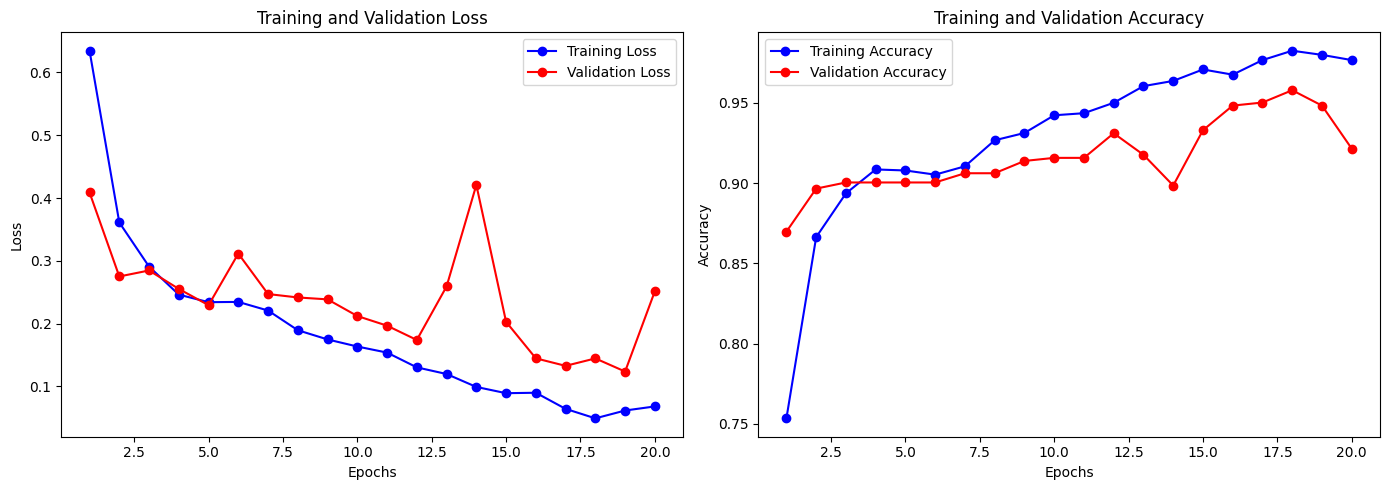

In [12]:
# Curvas de treino/validacao (usa o history vivo deste fit).
viz.plot_training_history(baseline_history)


### 2.2.1 Baseline + Classweight

O conjunto de dados é desequilibrado: a classe *cataract* representa apenas ~15% das
imagens, contra ~42% para *diabetic_retinopathy* e *normal*. Num modelo treinado sem
correção, esta sub-representação tende a penalizar a deteção da classe minoritária.

Este aspeto é especialmente relevante para o caso de uso (referenciação
hospitalar): uma catarata não detetada corresponde a um doente que não é encaminhado
para avaliação especializada. Por isso, a deteção da classe minoritária — medida pelo
*recall* da *cataract* — é uma prioridade.

Para mitigar o desequilíbrio, foi treinada uma segunda versão do baseline com **pesos de
classe** (`class_weight="balanced"`), que atribui a cada classe um peso inversamente
proporcional à sua frequência, penalizando mais os erros na classe minoritária.
Comparamos as duas versões com foco no *recall* da *cataract* para fundamentar a
decisão de adotar (ou não) esta técnica.

In [ ]:
# Limpar a sessão do TensorFlow para evitar conflitos com modelos anteriores
tf.keras.backend.clear_session()
# Definir seed para garantir reprodutibilidade dos resultados
tf.keras.utils.set_random_seed(SEED)

# CNN Baseline com Class Weight
# Arquitectura idêntica ao baseline anterior -- a única diferença é o class_weight,
# que penaliza mais os erros na classe minoritária (catarata) durante o treino.

model_baseline_classweight = models.Sequential([
    layers.Input(shape=X_train.shape[1:]),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dense(3, activation="softmax")
])

model_baseline_classweight.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# early stop para evitar overfitting e restaurar os melhores pesos
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

nome_baseline_cw = "Baseline (class weight)"
checkpoint_baseline_cw = ModelCheckpoint(
    filepath=str(MODELS_DIR / f"{data.slug(nome_baseline_cw)}.keras"),
    monitor="val_loss",
    save_best_only=True,
)

baseline_history_classweight = model_baseline_classweight.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    callbacks=[early_stop, checkpoint_baseline_cw],
    verbose=2,
    class_weight = class_weight,  # penaliza erros na catarata proporcionalmente à sub-representação
)

# adicionar o modelo com class weight à lista de avaliação
data.guardar_modelo(nome_baseline_cw, MODELS_DIR)
adicionar_modelo(nome_baseline_cw, model_baseline_classweight, baseline_history_classweight, X_test)

Epoch 1/20
49/49 - 14s - 280ms/step - accuracy: 0.7229 - loss: 0.7051 - val_accuracy: 0.8602 - val_loss: 0.3459
Epoch 2/20
49/49 - 15s - 305ms/step - accuracy: 0.8384 - loss: 0.4505 - val_accuracy: 0.8889 - val_loss: 0.2565
Epoch 3/20
49/49 - 5s - 98ms/step - accuracy: 0.8624 - loss: 0.3825 - val_accuracy: 0.9042 - val_loss: 0.2214
Epoch 4/20
49/49 - 3s - 71ms/step - accuracy: 0.8670 - loss: 0.3576 - val_accuracy: 0.8985 - val_loss: 0.2320
Epoch 5/20
49/49 - 3s - 71ms/step - accuracy: 0.8715 - loss: 0.3579 - val_accuracy: 0.9004 - val_loss: 0.2290
Epoch 6/20
49/49 - 4s - 82ms/step - accuracy: 0.8962 - loss: 0.3137 - val_accuracy: 0.9080 - val_loss: 0.2250
Epoch 7/20
49/49 - 5s - 108ms/step - accuracy: 0.9163 - loss: 0.2655 - val_accuracy: 0.9119 - val_loss: 0.2188
Epoch 8/20
49/49 - 4s - 83ms/step - accuracy: 0.9117 - loss: 0.2590 - val_accuracy: 0.9234 - val_loss: 0.2042
Epoch 9/20
49/49 - 4s - 90ms/step - accuracy: 0.9247 - loss: 0.2253 - val_accuracy: 0.9444 - val_loss: 0.1501
Epoch

Última train accuracy: 0.9727449417114258
Última val accuracy:   0.946360170841217
Melhor train accuracy: 0.9818300008773804
Melhor val accuracy:   0.959770143032074


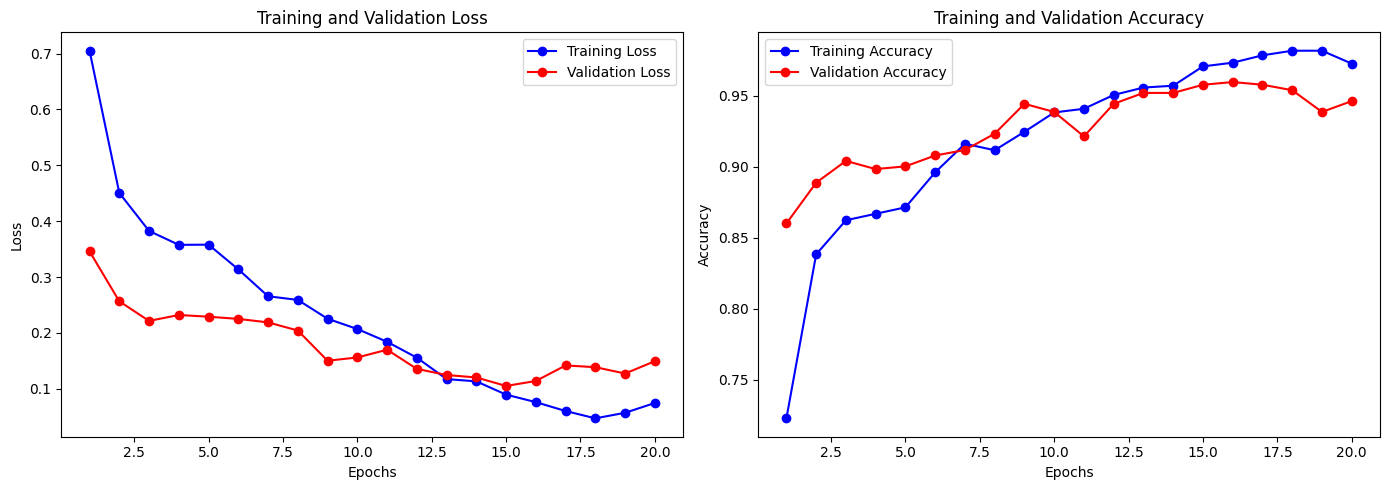

In [14]:
# Curvas de treino/validacao (usa o history vivo deste fit).
viz.plot_training_history(baseline_history_classweight)


### 2.3 CNN Regularizada
#### Afinação da Regularização

Tendo fixado o baseline com pesos de classe como modelo de referência, exploramos de
forma sistemática o efeito da **regularização**, motivados pela ligeira folga entre o
desempenho em treino e em validação observada nas curvas anteriores.

É testado duas técnicas de regularização complementares através de um *grid search*:

- **Regularização L2**: penaliza pesos de grande magnitude, favorecendo soluções mais
  suaves e reduzindo a dependência do modelo em características específicas do conjunto
  de treino.
- **Dropout**: desativa aleatoriamente uma fração de neurónios durante o treino,
  evitando a coadaptação entre neurónios e promovendo representações mais robustas.

As duas técnicas atuam em planos distintos — o L2 sobre a magnitude dos pesos, o dropout
sobre a estrutura da rede — pelo que são frequentemente combinadas. É realizada uma
pesquisa em grelha reduzida sobre os dois parâmetros, incluindo a configuração **sem
regularização** como referência, e mantendo fixos os restantes elementos (arquitetura,
*learning rate*, pesos de classe e *early stopping*) para isolar o efeito da
regularização.

A seleção é feita com base no **F1-*macro*** na validação — e não na *accuracy* — por
ponderar as três classes por igual, evitando que o desempenho nas classes maioritárias
mascare a deteção da *cataract*, prioritária para o nosso caso de uso.

In [15]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

def build_model(l2_value=0.0, dropout_value=0.0):
    """
    Constrói uma CNN com 3 blocos Conv2D + MaxPooling e uma camada densa.
    Regularização L2 e Dropout configuráveis — se l2_value=0 não aplica regularização,
    permitindo incluir a configuração sem regularização como referência no grid search.
    """
    reg = regularizers.l2(l2_value) if l2_value > 0 else None  # sem reg se l2=0
    model = models.Sequential([
        layers.Input(shape=X_train.shape[1:]),
        layers.Conv2D(32,  (3,3), activation="relu", kernel_regularizer=reg),
        layers.MaxPooling2D((2,2)),
        layers.Conv2D(64,  (3,3), activation="relu", kernel_regularizer=reg),
        layers.MaxPooling2D((2,2)),
        layers.Conv2D(128, (3,3), activation="relu", kernel_regularizer=reg),
        layers.MaxPooling2D((2,2)),
        layers.Flatten(),
        layers.Dense(128, activation="relu", kernel_regularizer=reg),
        layers.Dropout(dropout_value),
        layers.Dense(3, activation="softmax"),
    ])
    model.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

In [16]:
def cnn_grid_search():
    """
    Grid search sobre L2 e Dropout para a CNN treinada de raiz.
    Testa 9 combinações (3 valores de L2 × 3 valores de Dropout).
    Seleciona com base no F1-macro na validação — mais robusto ao
    desequilíbrio de classes do que a accuracy.
    """
    l2_values      = [0, 0.0001, 0.001]
    dropout_values = [0, 0.3, 0.5]
    resultados     = []

    for l2_v, drop_v in product(l2_values, dropout_values):
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(SEED)
        print(f"=== L2={l2_v}  dropout={drop_v} ===")

        model = build_model(l2_v, drop_v)
        es    = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
        model.fit(X_train, y_train,
                  validation_data=(X_val, y_val),
                  epochs=15, batch_size=32,
                  class_weight=class_weight,
                  callbacks=[es], verbose=0)

        # avaliar na validação — critério de selecção: F1-macro
        y_pred  = np.argmax(model.predict(X_val, verbose=0), axis=1)
        f1m     = f1_score(y_val, y_pred, average="macro")
        rec_cat = recall_score(y_val, y_pred, labels=[0], average="macro")
        resultados.append({"l2": l2_v, "dropout": drop_v,
                           "f1_macro": float(f1m), "recall_catarata": float(rec_cat)})
        print(f"   F1-macro={f1m:.4f}  recall_catarata={rec_cat:.4f}")

    # ordenar por F1-macro e mostrar ranking completo
    resultados.sort(key=lambda r: r["f1_macro"], reverse=True)
    print("\n===== RANKING =====")
    for r in resultados:
        print(f"F1={r['f1_macro']:.4f}  rec_cat={r['recall_catarata']:.4f}"
              f"  <-  L2={r['l2']}  dropout={r['dropout']}")
    return resultados[0]  # devolver os melhores hiperparâmetros

In [ ]:
def aplicar_melhor_cnn(best_params):
    """
    Treina o modelo CNN final com os melhores hiperparâmetros do grid search.
    Usa learning rate reduzido (0.0005) e mais epochs face ao grid search,
    permitindo uma convergência mais fina.
    """
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    model = build_model(best_params["l2"], best_params["dropout"])
    model.compile(optimizer=optimizers.Adam(learning_rate=0.0005),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])

    es = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
    checkpoint = ModelCheckpoint(
        filepath=str(MODELS_DIR / f"{data.slug('Regularizado')}.keras"),
        monitor="val_loss",
        save_best_only=True,
    )

    history = model.fit(X_train, y_train,
                        validation_data=(X_val, y_val),
                        epochs=30, batch_size=32,
                        class_weight=class_weight,
                        callbacks=[es, checkpoint], verbose=2)
    data.guardar_modelo("Regularizado", MODELS_DIR)
    adicionar_modelo("Regularizado", model, history, X_test, X_train, y_train)
    return model, history

In [18]:
# ── Executar Grid Search e treinar o modelo final ────────────
best_cnn = cnn_grid_search()
model_regularized, regularized_history = aplicar_melhor_cnn(best_cnn)

=== L2=0  dropout=0 ===
   F1-macro=0.8196  recall_catarata=0.4133
=== L2=0  dropout=0.3 ===
   F1-macro=0.9403  recall_catarata=0.8667
=== L2=0  dropout=0.5 ===
   F1-macro=0.8079  recall_catarata=0.4133
=== L2=0.0001  dropout=0 ===
   F1-macro=0.9412  recall_catarata=0.8533
=== L2=0.0001  dropout=0.3 ===
   F1-macro=0.8859  recall_catarata=0.7067
=== L2=0.0001  dropout=0.5 ===
   F1-macro=0.7998  recall_catarata=0.3467
=== L2=0.001  dropout=0 ===
   F1-macro=0.9482  recall_catarata=0.9333
=== L2=0.001  dropout=0.3 ===
   F1-macro=0.9496  recall_catarata=0.8533
=== L2=0.001  dropout=0.5 ===
   F1-macro=0.8197  recall_catarata=0.3867

===== RANKING =====
F1=0.9496  rec_cat=0.8533  <-  L2=0.001  dropout=0.3
F1=0.9482  rec_cat=0.9333  <-  L2=0.001  dropout=0
F1=0.9412  rec_cat=0.8533  <-  L2=0.0001  dropout=0
F1=0.9403  rec_cat=0.8667  <-  L2=0  dropout=0.3
F1=0.8859  rec_cat=0.7067  <-  L2=0.0001  dropout=0.3
F1=0.8197  rec_cat=0.3867  <-  L2=0.001  dropout=0.5
F1=0.8196  rec_cat=0.4133

Última train accuracy: 0.9591174721717834
Última val accuracy:   0.9731800556182861
Melhor train accuracy: 0.9682024717330933
Melhor val accuracy:   0.9731800556182861


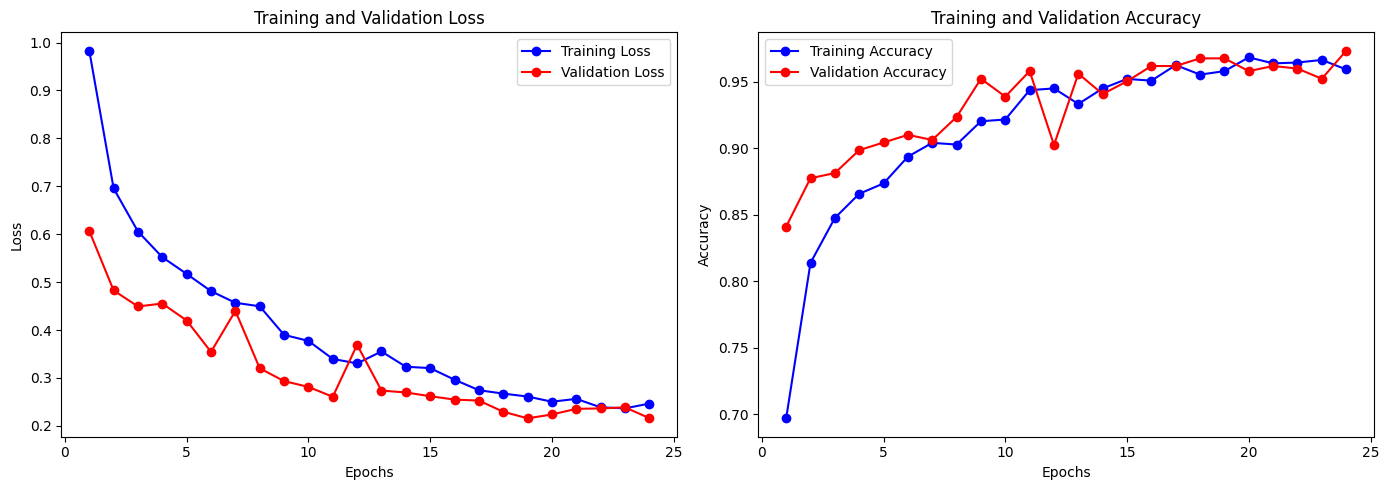

In [19]:
# Curvas de treino/validacao (usa o history vivo deste fit).
viz.plot_training_history(regularized_history)


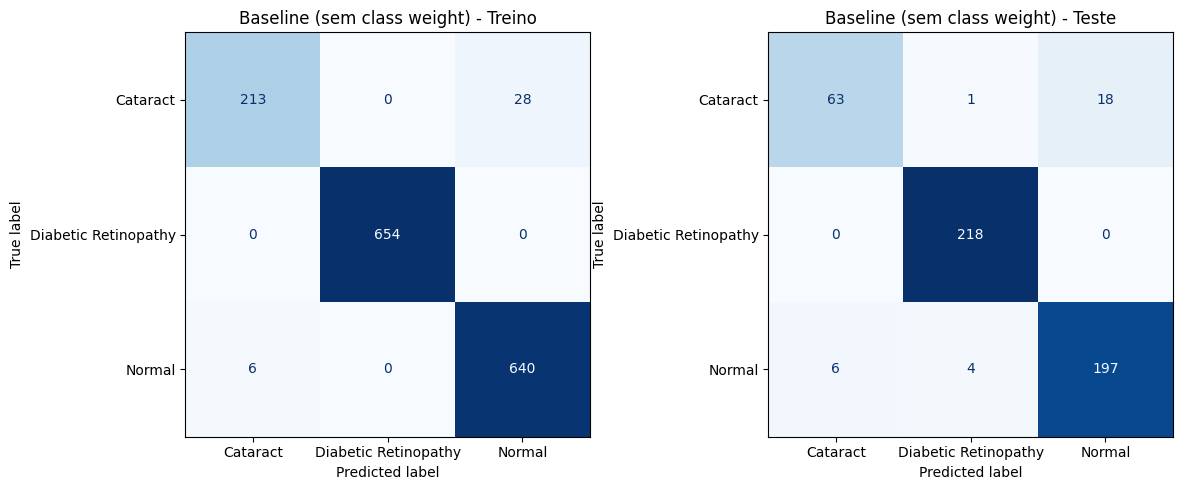

=== Baseline (sem class weight) | TREINO ===
              precision    recall  f1-score   support

           0       0.97      0.88      0.93       241
           1       1.00      1.00      1.00       654
           2       0.96      0.99      0.97       646

    accuracy                           0.98      1541
   macro avg       0.98      0.96      0.97      1541
weighted avg       0.98      0.98      0.98      1541

=== Baseline (sem class weight) | TESTE ===
              precision    recall  f1-score   support

           0       0.91      0.77      0.83        82
           1       0.98      1.00      0.99       218
           2       0.92      0.95      0.93       207

    accuracy                           0.94       507
   macro avg       0.94      0.91      0.92       507
weighted avg       0.94      0.94      0.94       507




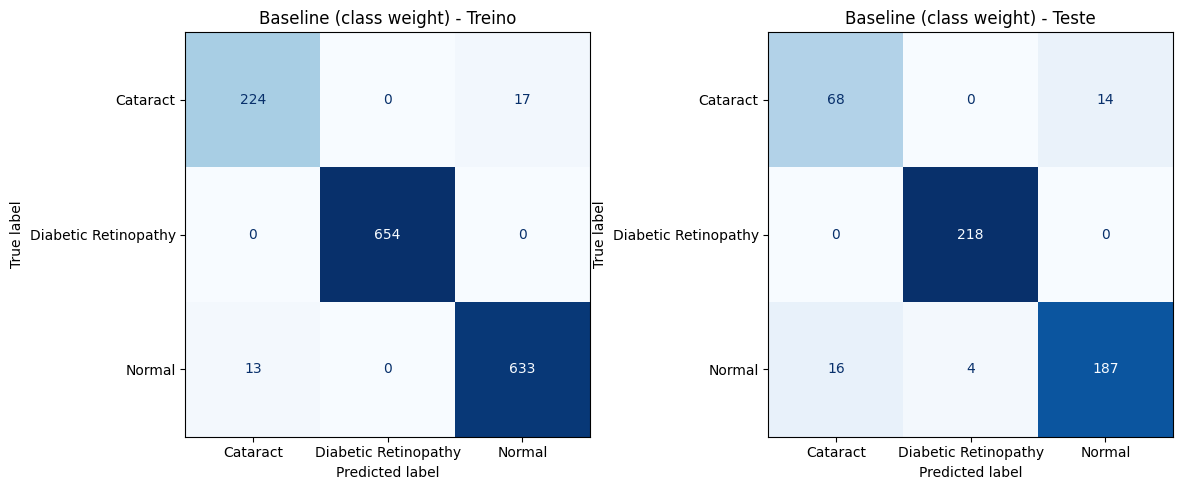

=== Baseline (class weight) | TREINO ===
              precision    recall  f1-score   support

           0       0.95      0.93      0.94       241
           1       1.00      1.00      1.00       654
           2       0.97      0.98      0.98       646

    accuracy                           0.98      1541
   macro avg       0.97      0.97      0.97      1541
weighted avg       0.98      0.98      0.98      1541

=== Baseline (class weight) | TESTE ===
              precision    recall  f1-score   support

           0       0.81      0.83      0.82        82
           1       0.98      1.00      0.99       218
           2       0.93      0.90      0.92       207

    accuracy                           0.93       507
   macro avg       0.91      0.91      0.91       507
weighted avg       0.93      0.93      0.93       507




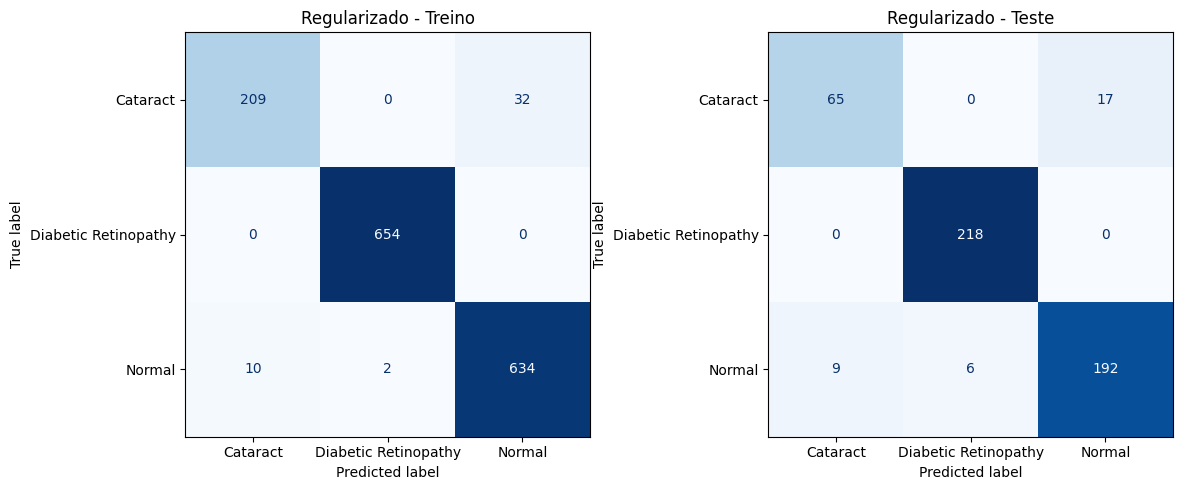

=== Regularizado | TREINO ===
              precision    recall  f1-score   support

           0       0.95      0.87      0.91       241
           1       1.00      1.00      1.00       654
           2       0.95      0.98      0.97       646

    accuracy                           0.97      1541
   macro avg       0.97      0.95      0.96      1541
weighted avg       0.97      0.97      0.97      1541

=== Regularizado | TESTE ===
              precision    recall  f1-score   support

           0       0.88      0.79      0.83        82
           1       0.97      1.00      0.99       218
           2       0.92      0.93      0.92       207

    accuracy                           0.94       507
   macro avg       0.92      0.91      0.91       507
weighted avg       0.94      0.94      0.94       507



In [20]:
# Diagnostico treino-vs-teste (overfitting) de cada modelo deste notebook

for nome, modelo, history, X_t, X_tr, y_tr, proba_te, proba_tr in modelos_treinados:
    print("\n" + "="*55)
    viz.plot_train_test_confusion(proba_tr, y_tr, proba_te, y_test, class_names, nome_modelo=nome)


In [ ]:
# as métricas de cada modelo persistem em artifacts/results.csv 

for nome, modelo, history, X_t, X_tr, y_tr, proba_te, proba_tr in modelos_treinados:
    row = data.compute_metrics_row(nome, proba_te, y_test, class_names)
    data.append_results_row(row, ARTIFACTS_DIR / "results.csv")
print("results.csv atualizado.")


results.csv atualizado.


: 